# Capítulo 3 · Limpieza de datos y outliers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_03/04_limpieza_y_outliers.ipynb)

**Preprocesamiento para Machine Learning · Parte 1 de 2**

---

### ¿Por qué limpiar los datos?

En Machine Learning se dice ***garbage in, garbage out***: basura entra, basura sale. Un modelo aprende de los datos que le das. Si tienen filas duplicadas, valores faltantes o errores, el modelo **aprende esos errores**. Además, la mayoría de modelos (regresión lineal, KNN, redes neuronales…) **no aceptan** valores faltantes ni texto.

El preprocesamiento es todo lo que pasa entre los datos crudos y el modelo:

```
datos crudos → diagnóstico → limpieza estructural → valores faltantes → outliers     ← esta clase
             → transformación → codificación → escalado → train/test → modelo        ← próxima clase
```

### 🎯 Objetivos
1. Diagnosticar la calidad de un dataset con un checklist.
2. Corregir duplicados, texto inconsistente y tipos de datos.
3. Decidir entre eliminar o imputar valores faltantes, a mano y con scikit-learn.
4. Detectar outliers con z-score, IQR y criterio de negocio.
5. Tratar outliers: eliminar o winsorizar.

### 📚 Índice
1. Diagnóstico de calidad
2. Limpieza estructural
3. Valores faltantes
4. Outliers: detección
5. Outliers: tratamiento
6. Resumen: antes y después
7. Chuleta resumen

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## 1. Diagnóstico de calidad

Antes de tocar nada, **se mira**. Este checklist sirve para cualquier dataset nuevo:

| Pregunta | Herramienta |
|---|---|
| ¿Cuántas filas y columnas hay? | `df.shape`, `df.head()` |
| ¿Cada columna tiene el tipo correcto? | `df.info()`, `df.dtypes` |
| ¿Faltan valores? ¿Cuántos? | `df.isna().sum()` |
| ¿Hay filas repetidas? | `df.duplicated().sum()` |
| ¿Las categorías están bien escritas? | `df["col"].value_counts()` |
| ¿Hay valores imposibles o extremos? | `df.describe()` |

Trabajaremos con `viviendas_sucio.csv`: las viviendas del notebook de pandas, pero **como llegarían en la vida real**. Tiene dos columnas nuevas: `estado` (estado de conservación) y `distancia_metro_m` (distancia a la estación de metro más cercana, en metros).

In [2]:
df = pd.read_csv(DATA_DIR / "viviendas_sucio.csv")
print("Forma:", df.shape)
df.head()

Forma: (612, 10)


,id,fecha_venta,barrio,metros,habitaciones,antiguedad,garaje,estado,distancia_metro_m,precio
0,404,2022-10-24,Centro,104.0,2,18.0,sí,buen estado,254.0,372000.0
1,458,2024-04-12,Sur,74.0,1,13.0,no,como nuevo,2369.0,128400.0
2,501,2023-09-12,Este,174.0,5,7.0,sí,como nuevo,1336.0,438200.0
3,85,2024-11-02,Centro,89.0,1,32.0,sí,a reformar,850.0,309700.0
4,110,2023-10-12,Oeste,114.0,4,0.0,no,como nuevo,379.0,306000.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 612 non-null    int64  
 1   fecha_venta        612 non-null    str    
 2   barrio             604 non-null    str    
 3   metros             580 non-null    float64
 4   habitaciones       612 non-null    int64  
 5   antiguedad         592 non-null    float64
 6   garaje             612 non-null    str    
 7   estado             596 non-null    str    
 8   distancia_metro_m  612 non-null    float64
 9   precio             612 non-null    str    
dtypes: float64(3), int64(2), str(5)
memory usage: 47.9 KB


> 🔍 Dos alarmas en `info()`:
> - `precio` aparece como **texto** (`str`), cuando debería ser un número.
> - `barrio`, `metros`, `antiguedad` y `estado` tienen **menos valores no nulos** que filas: faltan datos.

In [4]:
# Valores faltantes: cantidad y porcentaje por columna
pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(1),
})

,nulos,porcentaje
id,0,0.0
fecha_venta,0,0.0
barrio,8,1.3
metros,32,5.2
habitaciones,0,0.0
antiguedad,20,3.3
garaje,0,0.0
estado,16,2.6
distancia_metro_m,0,0.0
precio,0,0.0


In [5]:
# Filas con algún valor faltante (axis=1: ¿hay algún NaN en la fila?)
df[df.isna().any(axis=1)].head()

,id,fecha_venta,barrio,metros,habitaciones,antiguedad,garaje,estado,distancia_metro_m,precio
14,399,2023-08-02,Sur,59.0,1,NaN,no,a reformar,1991.0,130000.0
31,69,2023-06-12,Centro,86.0,2,54.0,no,NaN,445.0,273100.0
33,131,2022-06-25,Centro,NaN,4,46.0,sí,a reformar,54.0,378200.0
41,370,2023-03-22,Oeste,100.0,4,NaN,no,a reformar,1588.0,"$242,800"
46,277,2022-09-23,Norte,NaN,2,36.0,no,a reformar,1027.0,254600.0


In [6]:
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 12


In [7]:
# Categorías: ¿están bien escritas?
for col in ["barrio", "garaje", "estado"]:
    print(df[col].value_counts(dropna=False), "\n")

barrio
Centro       129
Norte        127
Sur          118
Oeste        114
Este          91
NaN            8
  norte        6
  sur          5
  centro       3
SUR            3
OESTE          3
CENTRO         2
NORTE          2
  oeste        1
Name: count, dtype: int64 

garaje
no    359
sí    253
Name: count, dtype: int64 

estado
buen estado    246
a reformar     199
como nuevo     151
NaN             16
Name: count, dtype: int64 



In [8]:
# ¿Por qué el precio es texto? Veamos algunos valores
df.loc[df["precio"].str.startswith("$"), "precio"].head()

17    $188,600
41    $242,800
45    $207,000
61     $45,900
67    $278,100
Name: precio, dtype: str

In [9]:
df.describe()

,id,metros,habitaciones,antiguedad,distancia_metro_m
count,612.000000,580.000000,612.000000,592.000000,612.000000
mean,300.991830,89.581034,2.586601,29.344595,1321.116013
std,173.234253,29.467502,1.219328,17.346850,1614.983968
min,1.000000,30.000000,1.000000,0.000000,45.000000
25%,151.750000,70.750000,2.000000,14.000000,460.000000
50%,302.500000,90.000000,3.000000,28.000000,888.500000
75%,450.250000,109.000000,3.000000,45.000000,1687.000000
max,600.000000,185.000000,6.000000,59.000000,27230.000000


> 🔍 Fíjate en `distancia_metro_m`: la mediana (50%) es de unos 900 m, pero el máximo pasa de **27 km**. (El precio no aparece en `describe()` porque todavía es texto.)

**📋 Resultado del diagnóstico**

| Problema | Dónde | Se arregla en |
|---|---|---|
| Filas duplicadas | 12 filas | 2.1 |
| Texto inconsistente | `barrio` ("Centro", "CENTRO", "  centro ") | 2.2 |
| Tipos incorrectos | `precio` (texto con `$` y comas), `fecha_venta` | 2.3 |
| Valores faltantes | `barrio`, `metros`, `antiguedad`, `estado` | 3 |
| Valores extremos | `precio`, `distancia_metro_m` | 4 y 5 |

---
## 2. Limpieza estructural

Son errores de **formato**: no hay que decidir nada estadístico, solo corregirlos. Por eso se pueden hacer en cualquier momento (la próxima clase verás por qué esto importa).

### 2.1 Duplicados

In [10]:
df = df.drop_duplicates()
print("Filas tras eliminar duplicados:", len(df))

Filas tras eliminar duplicados: 600


> 💡 `drop_duplicates()` solo elimina filas **idénticas en todas las columnas**. Si dos filas tienen el mismo `id` pero algún valor distinto, no las detecta: usa `df.duplicated(subset=["id"])` para buscarlas.

### 2.2 Texto inconsistente

Para pandas, `"Centro"`, `"CENTRO"` y `"  centro "` son **tres valores distintos**. Los métodos `.str` arreglan toda la columna de una vez:

In [11]:
print("Antes:  ", df["barrio"].unique())
df["barrio"] = df["barrio"].str.strip().str.capitalize()
print("Después:", df["barrio"].unique())

Antes:   <StringArray>
[   'Centro',       'Sur',      'Este',     'Oeste', '  centro ',  '  norte ',
     'Norte',    'CENTRO',       'SUR',     'OESTE',    '  sur ',         nan,
  '  oeste ',     'NORTE']
Length: 14, dtype: str
Después: <StringArray>
['Centro', 'Sur', 'Este', 'Oeste', 'Norte', nan]
Length: 6, dtype: str


### 2.3 Tipos de datos

El precio tiene valores como `"$188,600"` mezclados con `"245300.0"`. Quitamos los símbolos y lo convertimos a número:

In [12]:
df["precio"] = (df["precio"]
                .str.replace("$", "", regex=False)
                .str.replace(",", "", regex=False))
df["precio"] = pd.to_numeric(df["precio"])

df["fecha_venta"] = pd.to_datetime(df["fecha_venta"])
df.dtypes

id                            int64
fecha_venta          datetime64[us]
barrio                          str
metros                      float64
habitaciones                  int64
antiguedad                  float64
garaje                          str
estado                          str
distancia_metro_m           float64
precio                      float64
dtype: object

> 💡 Si `pd.to_numeric` encuentra un valor que no puede convertir, da error. Con `pd.to_numeric(col, errors="coerce")` lo convierte en `NaN`. Es útil, pero **comprueba después cuántos NaN aparecieron**: cada uno es un dato que se perdió.

---
## 3. Valores faltantes ⭐

In [13]:
nulos = df.isna().sum()
nulos[nulos > 0]

barrio         8
metros        30
antiguedad    20
estado        15
dtype: int64

### 3.1 ¿Por qué faltan los datos?

La razón por la que falta un dato cambia lo que conviene hacer:

| Tipo | Ejemplo | Qué implica |
|---|---|---|
| **Al azar** | Se perdió una hoja del registro | Imputar es razonable |
| **Depende de otra variable** | Los metros faltan más en viviendas antiguas | Imputar usando esa otra variable (por grupo) |
| **Depende del propio valor** | Quien gana mucho no declara su sueldo | El hecho de faltar **es información**: guárdalo en una columna indicadora |

En la práctica casi nunca se sabe con certeza, pero hacerse la pregunta evita errores.

### 3.2 Estrategias

| Estrategia | Cuándo usarla |
|---|---|
| Eliminar filas | Pocos nulos y una variable imprescindible |
| Eliminar la columna | Casi toda la columna está vacía |
| Imputar con la **media** | Variable numérica simétrica y sin outliers |
| Imputar con la **mediana** | Variable numérica con outliers o asimétrica |
| Imputar con la **moda** | Variable categórica |
| Imputar **por grupo** | El valor depende de otra variable |
| Añadir un **indicador** | Que falte el dato puede ser informativo |

### 3.3 Eliminar filas

`barrio` solo falta en 8 filas (el 1.3%) y es una variable clave: inventarse el barrio de una vivienda sería peor que perder esas filas.

In [14]:
df = df.dropna(subset=["barrio"])
print("Filas:", len(df))

Filas: 592


### 3.4 Indicador de valor faltante

Antes de imputar, guardamos **qué filas no tenían el dato**. Así el modelo podrá aprender si que falte la antigüedad dice algo (por ejemplo, que el anuncio estaba incompleto).

In [15]:
df["antiguedad_faltante"] = df["antiguedad"].isna().astype(int)
df["antiguedad_faltante"].value_counts()

antiguedad_faltante
0    573
1     19
Name: count, dtype: int64

### 3.5 ¿Media o mediana?

La media se ve muy afectada por los valores extremos; la mediana, no. Mira la diferencia en el precio, que todavía tiene errores de tipeo:

In [16]:
print(f"Precio medio:   {df['precio'].mean():,.0f}")
print(f"Precio mediano: {df['precio'].median():,.0f}")

Precio medio:   258,451
Precio mediano: 241,950


Por eso, ante la duda, se imputa con la **mediana**. Rellenamos la antigüedad:

In [17]:
mediana = df["antiguedad"].median()
print("Desviación estándar antes:  ", round(df["antiguedad"].std(), 2))

df["antiguedad"] = df["antiguedad"].fillna(mediana)
print("Desviación estándar después:", round(df["antiguedad"].std(), 2))

Desviación estándar antes:   17.31
Desviación estándar después: 17.03


> ⚠️ Imputar con un solo valor **reduce la variabilidad**: todas las viviendas sin dato quedan con la misma antigüedad. Con pocos nulos no importa mucho; con muchos, distorsiona la distribución.

### 3.6 Moda para categóricas

Para una variable categórica no existe la media: se usa el valor **más frecuente** (la moda).

In [18]:
moda = df["estado"].mode()[0]       # mode() devuelve una Series: nos quedamos con el primer valor
print("Moda:", moda)

df["estado"] = df["estado"].fillna(moda)
df["estado"].value_counts()

Moda: buen estado


estado
buen estado    254
a reformar     191
como nuevo     147
Name: count, dtype: int64

> 💡 Otra opción es crear una categoría nueva, por ejemplo `"desconocido"`. Es más honesta cuando no hay una categoría claramente dominante.

### 3.7 Imputación por grupo

Los metros de una vivienda dependen mucho del número de habitaciones. Rellenar con la mediana global le daría ~90 m² tanto a un estudio como a una casa de 6 habitaciones:

In [19]:
df.groupby("habitaciones")["metros"].median()

habitaciones
1     59.0
2     82.5
3     96.5
4    108.0
5    131.0
6    157.5
Name: metros, dtype: float64

In [20]:
# transform("median") devuelve, para cada fila, la mediana de SU grupo
df["metros"] = df["metros"].fillna(df.groupby("habitaciones")["metros"].transform("median"))
print("Nulos en metros:", df["metros"].isna().sum())

Nulos en metros: 0


### 3.8 Con scikit-learn: `SimpleImputer`

scikit-learn hace lo mismo en dos pasos con nombre propio:
- **`fit`**: *aprende* el valor de relleno (la mediana, la moda…) a partir de los datos.
- **`transform`**: *aplica* ese valor a los datos.

Probémoslo con las columnas originales del CSV:

In [21]:
crudo = pd.read_csv(DATA_DIR / "viviendas_sucio.csv")[["metros", "antiguedad"]]

imputador = SimpleImputer(strategy="median")    # también: "mean", "most_frequent", "constant"
imputador.fit(crudo)                            # aprende la mediana de cada columna
print("Medianas aprendidas:", imputador.statistics_)

imputado = imputador.transform(crudo)           # devuelve un array de NumPy
print("Nulos después:", np.isnan(imputado).sum())

Medianas aprendidas: [90. 28.]
Nulos después: 0


> ⚠️ **¿Por qué separar `fit` y `transform`?** Porque en un proyecto real la mediana se aprende **solo con los datos de entrenamiento** y se aplica después a los de test. Si la calculas con todos los datos, el modelo "ve" información del test: es *data leakage*. En esta clase usamos todo el dataset para centrarnos en las técnicas; en la próxima lo haremos en el orden correcto.

In [22]:
print("Total de nulos en df:", df.isna().sum().sum())

Total de nulos en df: 0


---
## 4. Outliers: detección ⭐

Un **outlier** (valor atípico) es un valor muy alejado del resto. Hay dos tipos muy distintos:

- **Errores**: un cero de más, un sensor averiado, una edad de 250 años. Hay que corregirlos o eliminarlos.
- **Valores raros pero reales**: una mansión, un cliente que compra mucho. Son información valiosa.

Los métodos de detección solo **señalan candidatos**. Decidir qué es cada uno requiere mirar los datos y conocer el problema.

### 4.1 Detección visual

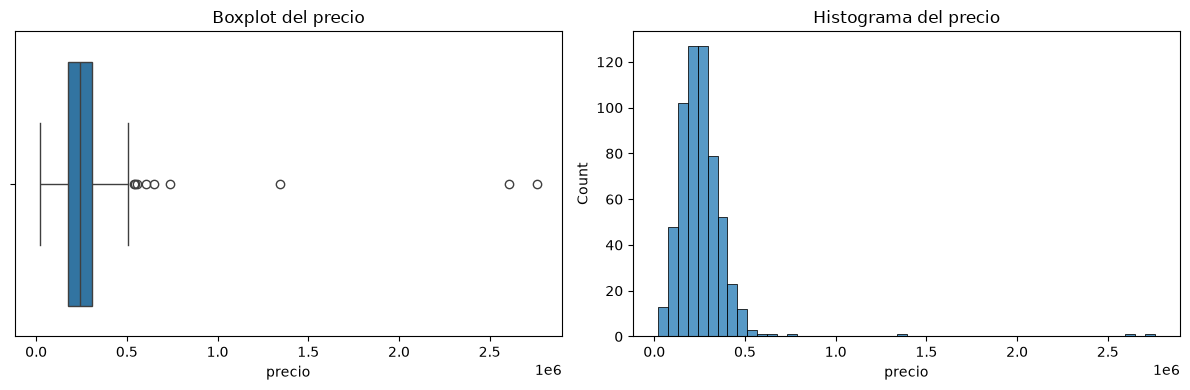

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["precio"], ax=axes[0])
axes[0].set_title("Boxplot del precio")
sns.histplot(df["precio"], bins=50, ax=axes[1])
axes[1].set_title("Histograma del precio")
plt.tight_layout()
plt.show()

Hay unos pocos precios de **millones**, muy lejos del resto. Veamos cómo detectarlos con números.

### 4.2 Z-score

El z-score mide **a cuántas desviaciones estándar** está cada valor de la media:

$$z = \frac{x - \text{media}}{\text{desviación estándar}}$$

Regla habitual: si $|z| > 3$, es un posible outlier.

In [24]:
z = (df["precio"] - df["precio"].mean()) / df["precio"].std()
print("Outliers por z-score:", (z.abs() > 3).sum())
df.loc[z.abs() > 3, ["barrio", "metros", "precio"]]

Outliers por z-score: 3


,barrio,metros,precio
202,Norte,92.0,2609000.0
289,Sur,62.0,1346000.0
298,Centro,82.0,2761000.0


> ⚠️ **El z-score tiene una trampa.** Usa la media y la desviación estándar, que se ven **infladas por los propios outliers**. Un outlier muy grande "estira" la desviación estándar y puede esconder a otros: se llama **enmascaramiento**. Enseguida veremos que aquí hay un error que el z-score no detecta.

### 4.3 Rango intercuartílico (IQR)

Usa los cuartiles, que **no se ven afectados** por los valores extremos:

- $IQR = Q_3 - Q_1$ (el rango donde está el 50% central de los datos)
- Son outliers los valores fuera de $[\,Q_1 - 1.5 \cdot IQR,\ \ Q_3 + 1.5 \cdot IQR\,]$

Es exactamente la regla que usa el boxplot para dibujar los puntos sueltos.

In [25]:
def limites_iqr(serie, k=1.5):
    """Devuelve los límites inferior y superior según la regla del IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


inf, sup = limites_iqr(df["precio"])
print(f"Rango aceptable: [{inf:,.0f}, {sup:,.0f}]")

atipicos_iqr = df[(df["precio"] < inf) | (df["precio"] > sup)]
print("Outliers por IQR:", len(atipicos_iqr))

Rango aceptable: [-31,538, 515,362]
Outliers por IQR: 9


### 4.4 Criterio de negocio

El IQR marca más candidatos, pero ¿son todos errores? Calculemos algo que tenga sentido en este negocio: el **precio por metro cuadrado**.

In [26]:
revision = atipicos_iqr[["barrio", "metros", "precio"]].copy()
revision["precio_m2"] = revision["precio"] / revision["metros"]
revision.sort_values("precio_m2").round(0)

,barrio,metros,precio,precio_m2
314,Centro,185.0,647900.0,3502.0
602,Centro,147.0,540500.0,3677.0
203,Centro,164.0,605300.0,3691.0
486,Centro,150.0,554700.0,3698.0
146,Centro,143.0,545300.0,3813.0
289,Sur,62.0,1346000.0,21710.0
392,Sur,30.0,740000.0,24667.0
202,Norte,92.0,2609000.0,28359.0
298,Centro,82.0,2761000.0,33671.0


El precio por m² separa claramente dos grupos:
- ~3.500–4.000 por m²: **viviendas grandes del Centro**. Caras, pero reales.
- Más de 15.000 por m²: imposible en este mercado. Es un **error de tipeo** (alguien escribió un cero de más).

In [27]:
errores = df["precio"] / df["metros"] > 10_000
print("Errores por criterio de negocio:", errores.sum())

Errores por criterio de negocio: 4


| Método | Detecta | Problema |
|---|---|---|
| Z-score | 3 | Se le escapa un error (enmascaramiento) |
| IQR | 9 | Mezcla los 4 errores con 5 viviendas caras reales |
| Criterio de negocio | 4 | Exactamente los errores, pero requiere conocer el problema |

> 🧠 **Moraleja**: los métodos estadísticos señalan candidatos; **el conocimiento del problema decide**.

### 4.5 Cuidado con las variables asimétricas

Apliquemos el IQR a la distancia al metro:

Límite superior: 3,526 m
Outliers por IQR: 32


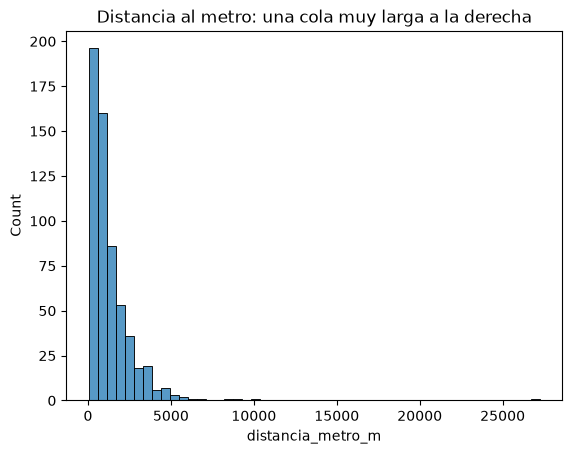

In [28]:
inf, sup = limites_iqr(df["distancia_metro_m"])
print(f"Límite superior: {sup:,.0f} m")
print("Outliers por IQR:", ((df["distancia_metro_m"] < inf) | (df["distancia_metro_m"] > sup)).sum())

fig, ax = plt.subplots()
sns.histplot(df["distancia_metro_m"], bins=50, ax=ax)
ax.set_title("Distancia al metro: una cola muy larga a la derecha")
plt.show()

El IQR marca decenas de viviendas como "atípicas", pero **no son errores**: muchas viviendas están cerca del metro y unas pocas, muy lejos. Es la **forma** de la distribución (asimétrica, con una cola larga). Eliminar esas filas sería perder datos válidos. La solución es **transformar** la variable con un logaritmo: lo veremos en la próxima clase.

---
## 5. Outliers: tratamiento

| Situación | Qué hacer |
|---|---|
| Es un **error** seguro | Eliminarlo (o corregirlo, si sabes cuál era el valor real) |
| Es real, pero **tan extremo que distorsiona** | Winsorizar: recortarlo a un límite |
| La variable tiene una **cola larga** | Transformarla con un logaritmo (próxima clase) |
| Es real e **informativo** | Dejarlo |

### 5.1 Eliminar errores

In [29]:
# Errores de tipeo: precio por m² imposible en este mercado (criterio de la sección 4.4)
errores = df["precio"] / df["metros"] > 10_000
print("Errores a eliminar:", errores.sum())

df = df[~errores]
print("Filas:", len(df))

inf, sup = limites_iqr(df["precio"])
print("Outliers por IQR que quedan:", ((df["precio"] < inf) | (df["precio"] > sup)).sum())

Errores a eliminar: 4
Filas: 588
Outliers por IQR que quedan: 5


Quedan 5 "outliers" según el IQR: las viviendas caras del Centro. **Las conservamos**: si las borráramos, el modelo nunca aprendería a predecir precios altos.

> 💡 Si supieras con certeza qué pasó (aquí, un cero de más), podrías **corregir** el valor dividiéndolo entre 10 en lugar de eliminar la fila. En la vida real rara vez hay esa certeza.

### 5.2 Winsorización (*capping*)

Consiste en **recortar** los valores extremos a un límite, normalmente los percentiles 1 y 99. No elimina filas: solo "acerca" los valores más extremos. Con pandas se hace con `clip`:

In [30]:
p01, p99 = df["distancia_metro_m"].quantile([0.01, 0.99])
print(f"Percentil 1: {p01:,.0f} m | Percentil 99: {p99:,.0f} m")

df["distancia_wins"] = df["distancia_metro_m"].clip(lower=p01, upper=p99)

df[["distancia_metro_m", "distancia_wins"]].describe().round(0)

Percentil 1: 79 m | Percentil 99: 5,619 m


,distancia_metro_m,distancia_wins
count,588.0,588.0
mean,1314.0,1256.0
std,1623.0,1124.0
min,45.0,79.0
25%,461.0,461.0
50%,882.0,882.0
75%,1680.0,1680.0
max,27230.0,5619.0


> 💡 El máximo baja de más de 27 km a unos 5.6 km, y el resto de valores no cambia. También se pueden usar los límites del IQR en lugar de los percentiles.

### 5.3 ¿Y si no hago nada?

No todos los outliers hay que tratarlos:
- Si son **reales e informativos** (las viviendas caras del Centro), son justo lo que el modelo tiene que aprender.
- Algunos modelos, como los **árboles de decisión**, son poco sensibles a los outliers.
- Las medidas basadas en la **mediana** y los cuartiles ya son robustas.

> 🧠 Trata los outliers **por un motivo**, no por costumbre.

---
## 6. Resumen: antes y después

In [31]:
original = pd.read_csv(DATA_DIR / "viviendas_sucio.csv")

pd.DataFrame({
    "antes": [len(original), original.isna().sum().sum(), original.duplicated().sum(),
              original["barrio"].nunique(), str(original["precio"].dtype)],
    "después": [len(df), df.isna().sum().sum(), df.duplicated().sum(),
                df["barrio"].nunique(), str(df["precio"].dtype)],
}, index=["filas", "valores nulos", "filas duplicadas", "barrios distintos", "tipo del precio"])

,antes,después
filas,612,588
valores nulos,76,0
filas duplicadas,12,0
barrios distintos,13,5
tipo del precio,str,float64


In [32]:
df.head()

,id,fecha_venta,barrio,metros,habitaciones,antiguedad,garaje,estado,distancia_metro_m,precio,antiguedad_faltante,distancia_wins
0,404,2022-10-24,Centro,104.0,2,18.0,sí,buen estado,254.0,372000.0,0,254.0
1,458,2024-04-12,Sur,74.0,1,13.0,no,como nuevo,2369.0,128400.0,0,2369.0
2,501,2023-09-12,Este,174.0,5,7.0,sí,como nuevo,1336.0,438200.0,0,1336.0
3,85,2024-11-02,Centro,89.0,1,32.0,sí,a reformar,850.0,309700.0,0,850.0
4,110,2023-10-12,Oeste,114.0,4,0.0,no,como nuevo,379.0,306000.0,0,379.0


✅ **Dataset limpio**: sin duplicados, sin nulos, con texto homogéneo, tipos correctos y sin errores de tipeo. Además tenemos una versión winsorizada de la distancia al metro (`distancia_wins`).

> ⚠️ **Recuerda**: las medianas, la moda y los percentiles los calculamos con **todo el dataset**. En la próxima clase separaremos *train* y *test* y lo haremos en el orden correcto, con un `Pipeline` de scikit-learn.

---
## 7. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Nulos por columna | `df.isna().sum()`, `df.isna().mean() * 100` |
| Filas con algún nulo | `df[df.isna().any(axis=1)]` |
| Duplicados | `df.duplicated().sum()`, `df.drop_duplicates()` |
| Limpiar texto | `df["c"].str.strip().str.capitalize()` |
| Texto a número | `pd.to_numeric(df["c"].str.replace("$", "", regex=False))` |
| Eliminar filas con nulos | `df.dropna(subset=["c"])` |
| Indicador de nulo | `df["c_faltante"] = df["c"].isna().astype(int)` |
| Imputar | `df["c"].fillna(df["c"].median())`, `.mode()[0]` |
| Imputar por grupo | `df["c"].fillna(df.groupby("g")["c"].transform("median"))` |
| Imputar con sklearn | `SimpleImputer(strategy="median").fit(X)`, `.transform(X)` |
| Z-score | `(s - s.mean()) / s.std()`, outlier si `abs(z) > 3` |
| IQR | `q1, q3 = s.quantile([0.25, 0.75])`, límites `q1 - 1.5*iqr`, `q3 + 1.5*iqr` |
| Winsorizar | `s.clip(lower=s.quantile(0.01), upper=s.quantile(0.99))` |

---
### 🎓 ¿Qué sigue?

Ya tienes datos limpios. En la próxima clase los dejaremos **listos para un modelo**: transformar variables, codificar las categóricas (`barrio`, `garaje`, `estado`), escalar, separar *train* y *test* sin *data leakage*, y unirlo todo en un `Pipeline` de scikit-learn.